In [ ]:
%pip install -q ultralytics ipywidgets matplotlib pandas pillow

In [ ]:
from ultralytics import YOLO
from PIL import Image
from IPython.display import display
import ipywidgets as widgets
import matplotlib.pyplot as plt
import pandas as pd
from collections import Counter
import io
import numpy as np

# Load the pretrained model. The weights download automatically on first use.
model = YOLO("yolov8n.pt")

print("YOLOv8 model loaded successfully.")
print("Inference device: CPU")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLOv8 model loaded successfully.
Inference device: CPU


In [ ]:
uploader = widgets.FileUpload(
    accept=".jpg,.jpeg,.png,.webp",
    multiple=False,
    description="Choose traffic photo"
)
display(uploader)

FileUpload(value={}, accept='.jpg,.jpeg,.png,.webp', description='Choose traffic photo')

Uploaded: uploaded_traffic_image
Image size: (1216, 886)


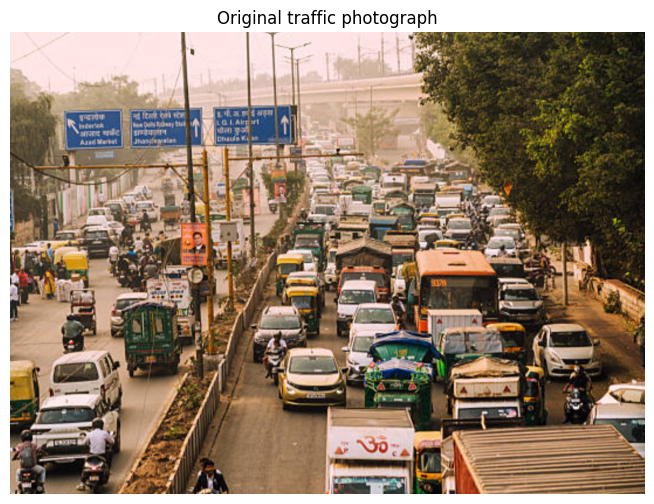

In [ ]:
def get_uploaded_file(upload_widget):
    value = upload_widget.value

    if not value:
        raise ValueError("No image uploaded. Run the upload cell and choose an image first.")

    # ipywidgets 8 generally returns a tuple of file dictionaries.
    if isinstance(value, dict):
        # Some ipywidgets versions return a dictionary keyed by filename.
        if "content" in value:
            file_info = value
        else:
            file_info = next(iter(value.values()))
    else:
        file_info = value[0]

    content = file_info["content"]
    image_bytes = bytes(content)
    filename = file_info.get("name", "uploaded_traffic_image")
    return Image.open(io.BytesIO(image_bytes)).convert("RGB"), filename

traffic_image, image_filename = get_uploaded_file(uploader)

print("Uploaded:", image_filename)
print("Image size:", traffic_image.size)

plt.figure(figsize=(10, 6))
plt.imshow(traffic_image)
plt.axis("off")
plt.title("Original traffic photograph")
plt.show()

In [ ]:
CONFIDENCE_THRESHOLD = 0.25  # Try 0.40 or 0.50 for stricter detections
IMAGE_SIZE = 640             # Try 416 for faster CPU inference

results = model.predict(
    source=traffic_image,
    conf=CONFIDENCE_THRESHOLD,
    imgsz=IMAGE_SIZE,
    device="cpu",
    verbose=False
)

result = results[0]
print("Detection completed.")

Detection completed.


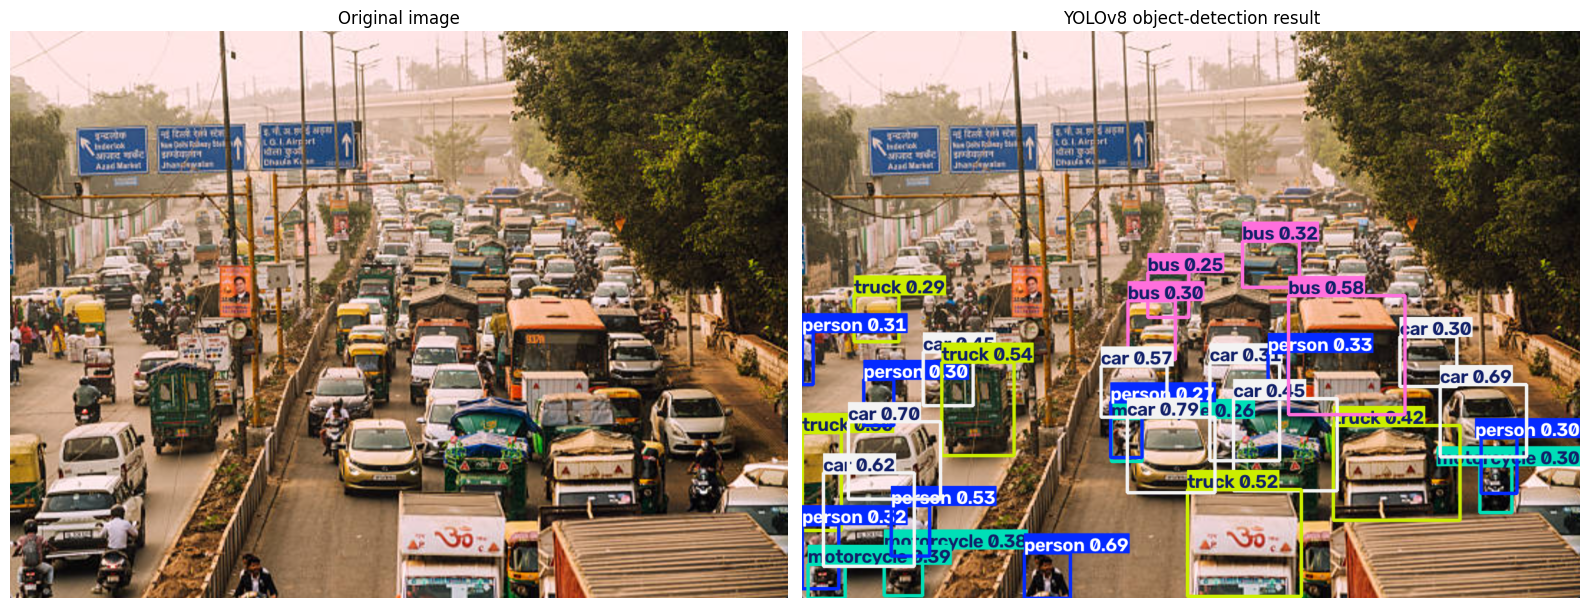

In [ ]:
# Ultralytics result.plot() returns a BGR image; convert it to RGB for Matplotlib.
annotated_bgr = result.plot()
annotated_rgb = annotated_bgr[:, :, ::-1]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].imshow(traffic_image)
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(annotated_rgb)
axes[1].set_title("YOLOv8 object-detection result")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
detection_rows = []

if result.boxes is not None:
    for box in result.boxes:
        class_id = int(box.cls.item())
        detection_rows.append({
            "Object": result.names[class_id],
            "Confidence": round(float(box.conf.item()), 3),
            "X-min": round(float(box.xyxy[0][0].item()), 1),
            "Y-min": round(float(box.xyxy[0][1].item()), 1),
            "X-max": round(float(box.xyxy[0][2].item()), 1),
            "Y-max": round(float(box.xyxy[0][3].item()), 1),
        })

detections_df = pd.DataFrame(
    detection_rows,
    columns=["Object", "Confidence", "X-min", "Y-min", "X-max", "Y-max"]
)

if detections_df.empty:
    print("No objects detected. Try a clearer image or lower the confidence threshold.")
else:
    display(detections_df)

,Object,Confidence,X-min,Y-min,X-max,Y-max
0,car,0.790,509.0,603.1,645.0,721.8
1,car,0.697,72.2,610.0,216.3,731.1
2,person,0.690,347.7,815.3,420.0,886.0
3,car,0.685,997.1,552.7,1132.8,665.9
4,car,0.617,33.1,690.4,175.3,836.2
5,bus,0.583,760.9,413.5,942.0,599.9
6,car,0.570,467.4,523.0,570.7,603.8
7,truck,0.541,218.3,517.1,331.5,663.6
8,person,0.527,139.9,741.9,199.6,820.1
9,truck,0.515,602.5,716.1,780.6,883.1


In [ ]:
if detections_df.empty:
    print("No objects to count.")
else:
    object_counts = detections_df["Object"].value_counts().rename_axis("Object").reset_index(name="Count")
    display(object_counts)

    print("Total objects detected:", len(detections_df))
    print("Different object categories:", detections_df["Object"].nunique())

,Object,Count
0,car,9
1,person,8
2,truck,5
3,bus,4
4,motorcycle,4


Total objects detected: 30
Different object categories: 5


In [ ]:
# Save the annotated image in the current notebook folder.
annotated_image = Image.fromarray(annotated_rgb)
annotated_image.save("traffic_detection_result.jpg")

# Save detection details as a CSV file.
detections_df.to_csv("traffic_detection_results.csv", index=False)

print("Saved: traffic_detection_result.jpg")
print("Saved: traffic_detection_results.csv")

Saved: traffic_detection_result.jpg
Saved: traffic_detection_results.csv
